# M4.5 · 鲁棒优化与估计误差

> 均值-方差优化是「误差放大器」：期望收益 μ 与协方差 Σ 都来自有限历史样本，输入的微小扰动会被优化放大成极端角点解，样本外表现往往很差。
> 鲁棒优化通过**收缩、重采样、对角加载、不确定集**等手段，主动承认并控制估计误差。

## 一、估计误差为什么致命

1. **期望收益比协方差更难估计**：均值的标准误 $\propto 1/\sqrt{T}$，个股日频均值的截面差异常被抽样噪声淹没；
2. **James-Stein 收缩**：把各资产均值向全局均值 $\bar\mu$ 拉回，收缩因子
$$B=\frac{(m-2)\,s^2}{T\sum_i(\mu_i-\bar\mu)^2},\qquad
\mu_i^{JS}=\bar\mu+(1-B)(\mu_i-\bar\mu),\quad B\in[0,1]$$
3. **Michaud 重采样（1998）**：bootstrap 重抽历史，每次重新估计并优化，对权重平均；
4. **对角加载（worst-case）**：$\Sigma+\epsilon I$，等价于对协方差估计误差做稳健保护，抑制小特征值噪声；
5. **前沿不确定性**：用 bootstrap 给出有效前沿的置信带。

## 二、数据准备与期望收益收缩

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import robust
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
r30 = ret.iloc[-750:, :30].dropna(axis=1)
mu_js, shrink, raw_B = robust.shrink_mu(r30)
mu_raw = r30.mean() * 242
print('原始收缩因子 B=%.3f（>1 表示截面差异不显著，正向JS完全收缩）' % raw_B)
print('截断后 shrink=%.3f' % shrink)
print('原始年化mu: 均值=%.4f 标准差=%.4f' % (mu_raw.mean(), mu_raw.std()))
print('JS年化mu:  均值=%.4f 标准差=%.4f' % (mu_js.mean(), mu_js.std()))

[8944:MainThread](2026-11-05 14:37:02,690) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[8944:MainThread](2026-11-05 14:37:05,109) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[8944:MainThread](2026-11-05 14:37:05,111) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


原始收缩因子 B=1.440（>1 表示截面差异不显著，正向JS完全收缩）
截断后 shrink=1.000
原始年化mu: 均值=0.0914 标准差=0.1405
JS年化mu:  均值=0.0914 标准差=0.0000


## 三、Michaud 重采样与稳健最小方差

In [2]:
w_rs, W = robust.resampled_weights(r30, n_sims=30)
w_rv, eps, cnd = robust.robust_min_variance(r30)
print('重采样权重: sum=%.4f 非零=%d 最大权重=%.4f'
      % (w_rs.sum(), (w_rs > 1e-6).sum(), w_rs.max()))
print('对角加载 epsilon=%.7f 加载后条件数=%.1f' % (eps, cnd))
fu = robust.frontier_uncertainty(r30, n_sims=30, n_targets=8)
print('前沿带目标点数=%d, 波动均值范围[%.4f, %.4f]'
      % (len(fu['targets']), fu['vol_mean'].min(), fu['vol_mean'].max()))

重采样权重: sum=1.0000 非零=30 最大权重=0.3228


对角加载 epsilon=0.0000155 加载后条件数=59.0


前沿带目标点数=8, 波动均值范围[0.0083, 0.0099]


## 四、可视化

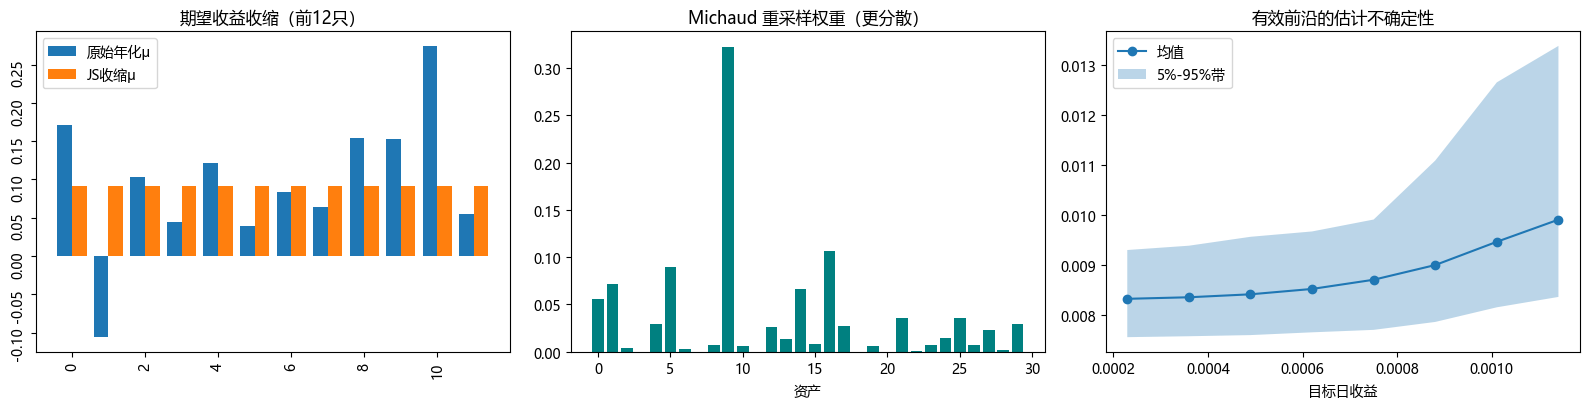

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
xx = np.arange(12)
ax[0].bar(xx-0.2, mu_raw.iloc[:12], 0.4, label='原始年化μ')
ax[0].bar(xx+0.2, mu_js.iloc[:12], 0.4, label='JS收缩μ')
ax[0].set_title('期望收益收缩（前12只）'); ax[0].legend(); ax[0].tick_params(labelrotation=90)
ax[1].bar(np.arange(30), w_rs.values, color='teal')
ax[1].set_title('Michaud 重采样权重（更分散）'); ax[1].set_xlabel('资产')
ax[2].plot(fu['targets'], fu['vol_mean'], 'o-', label='均值')
ax[2].fill_between(fu['targets'], fu['vol_p05'], fu['vol_p95'], alpha=0.3, label='5%-95%带')
ax[2].set_title('有效前沿的估计不确定性'); ax[2].set_xlabel('目标日收益'); ax[2].legend()
plt.tight_layout(); plt.show()

## 五、面试要点

- **为什么均值-方差在样本外常失效？** 期望收益估计误差大，优化器把高（噪声）μ 的资产权重推到角点，形成极端集中持仓。
- **James-Stein 收缩的直觉？** 单个均值是无偏但高方差估计；向共同均值适度收缩，用一点偏差换大幅方差下降，总 MSE 更小。本数据 B=1.44 说明个股历史均值差异在统计上不显著。
- **重采样 vs 收缩的区别？** 重采样平均的是「权重」，天然处理非线性的优化映射；收缩直接改输入。两者都让权重更分散稳定。
- **对角加载为何有效？** 抬高小特征值，降低条件数，等价于 Tikhonov 正则/worst-case 稳健性。

## 六、练习

1. 把窗口从 750 改为 250/1500，观察收缩因子 B 如何变化，解释 $T$ 的作用。
2. 调整 `n_sims`，看重采样权重的分散度是否随模拟次数收敛。
3. 推导：为什么 $\Sigma+\epsilon I$ 与 Tikhonov 正则化等价？
4. 思考：若用因子模型估计 μ（而非历史均值），收缩因子会如何变化？